In [1]:
# Load LCOH and CO2 results per heating strategy for each catalyst
import json
from pathlib import Path

# Catalyst name -> project sub-folder
CATALYST_FOLDERS = {"Fe": "FeMP", "AC": "ACMP", "Ni": "NiMP"}


def find_project_root():
    """Walk up from this notebook until a folder containing all catalyst folders is found."""
    try:
        start_dir = Path(__file__).resolve().parent
    except NameError:
        start_dir = Path.cwd()

    for path in [start_dir, *start_dir.parents]:
        if all((path / folder).is_dir() for folder in CATALYST_FOLDERS.values()):
            return path

    raise FileNotFoundError("Project root not found.")


def load_json(path):
    with open(path, "r") as f:
        return json.load(f)


project_root = find_project_root()

catalysts = {}
for name, folder in CATALYST_FOLDERS.items():
    results_dir = project_root / folder / "Results_TEA"
    catalysts[name] = {
        "lcoh": load_json(results_dir / "LCOH_heatings.json"),
        "co2": load_json(results_dir / "CO2_results.json"),
    }

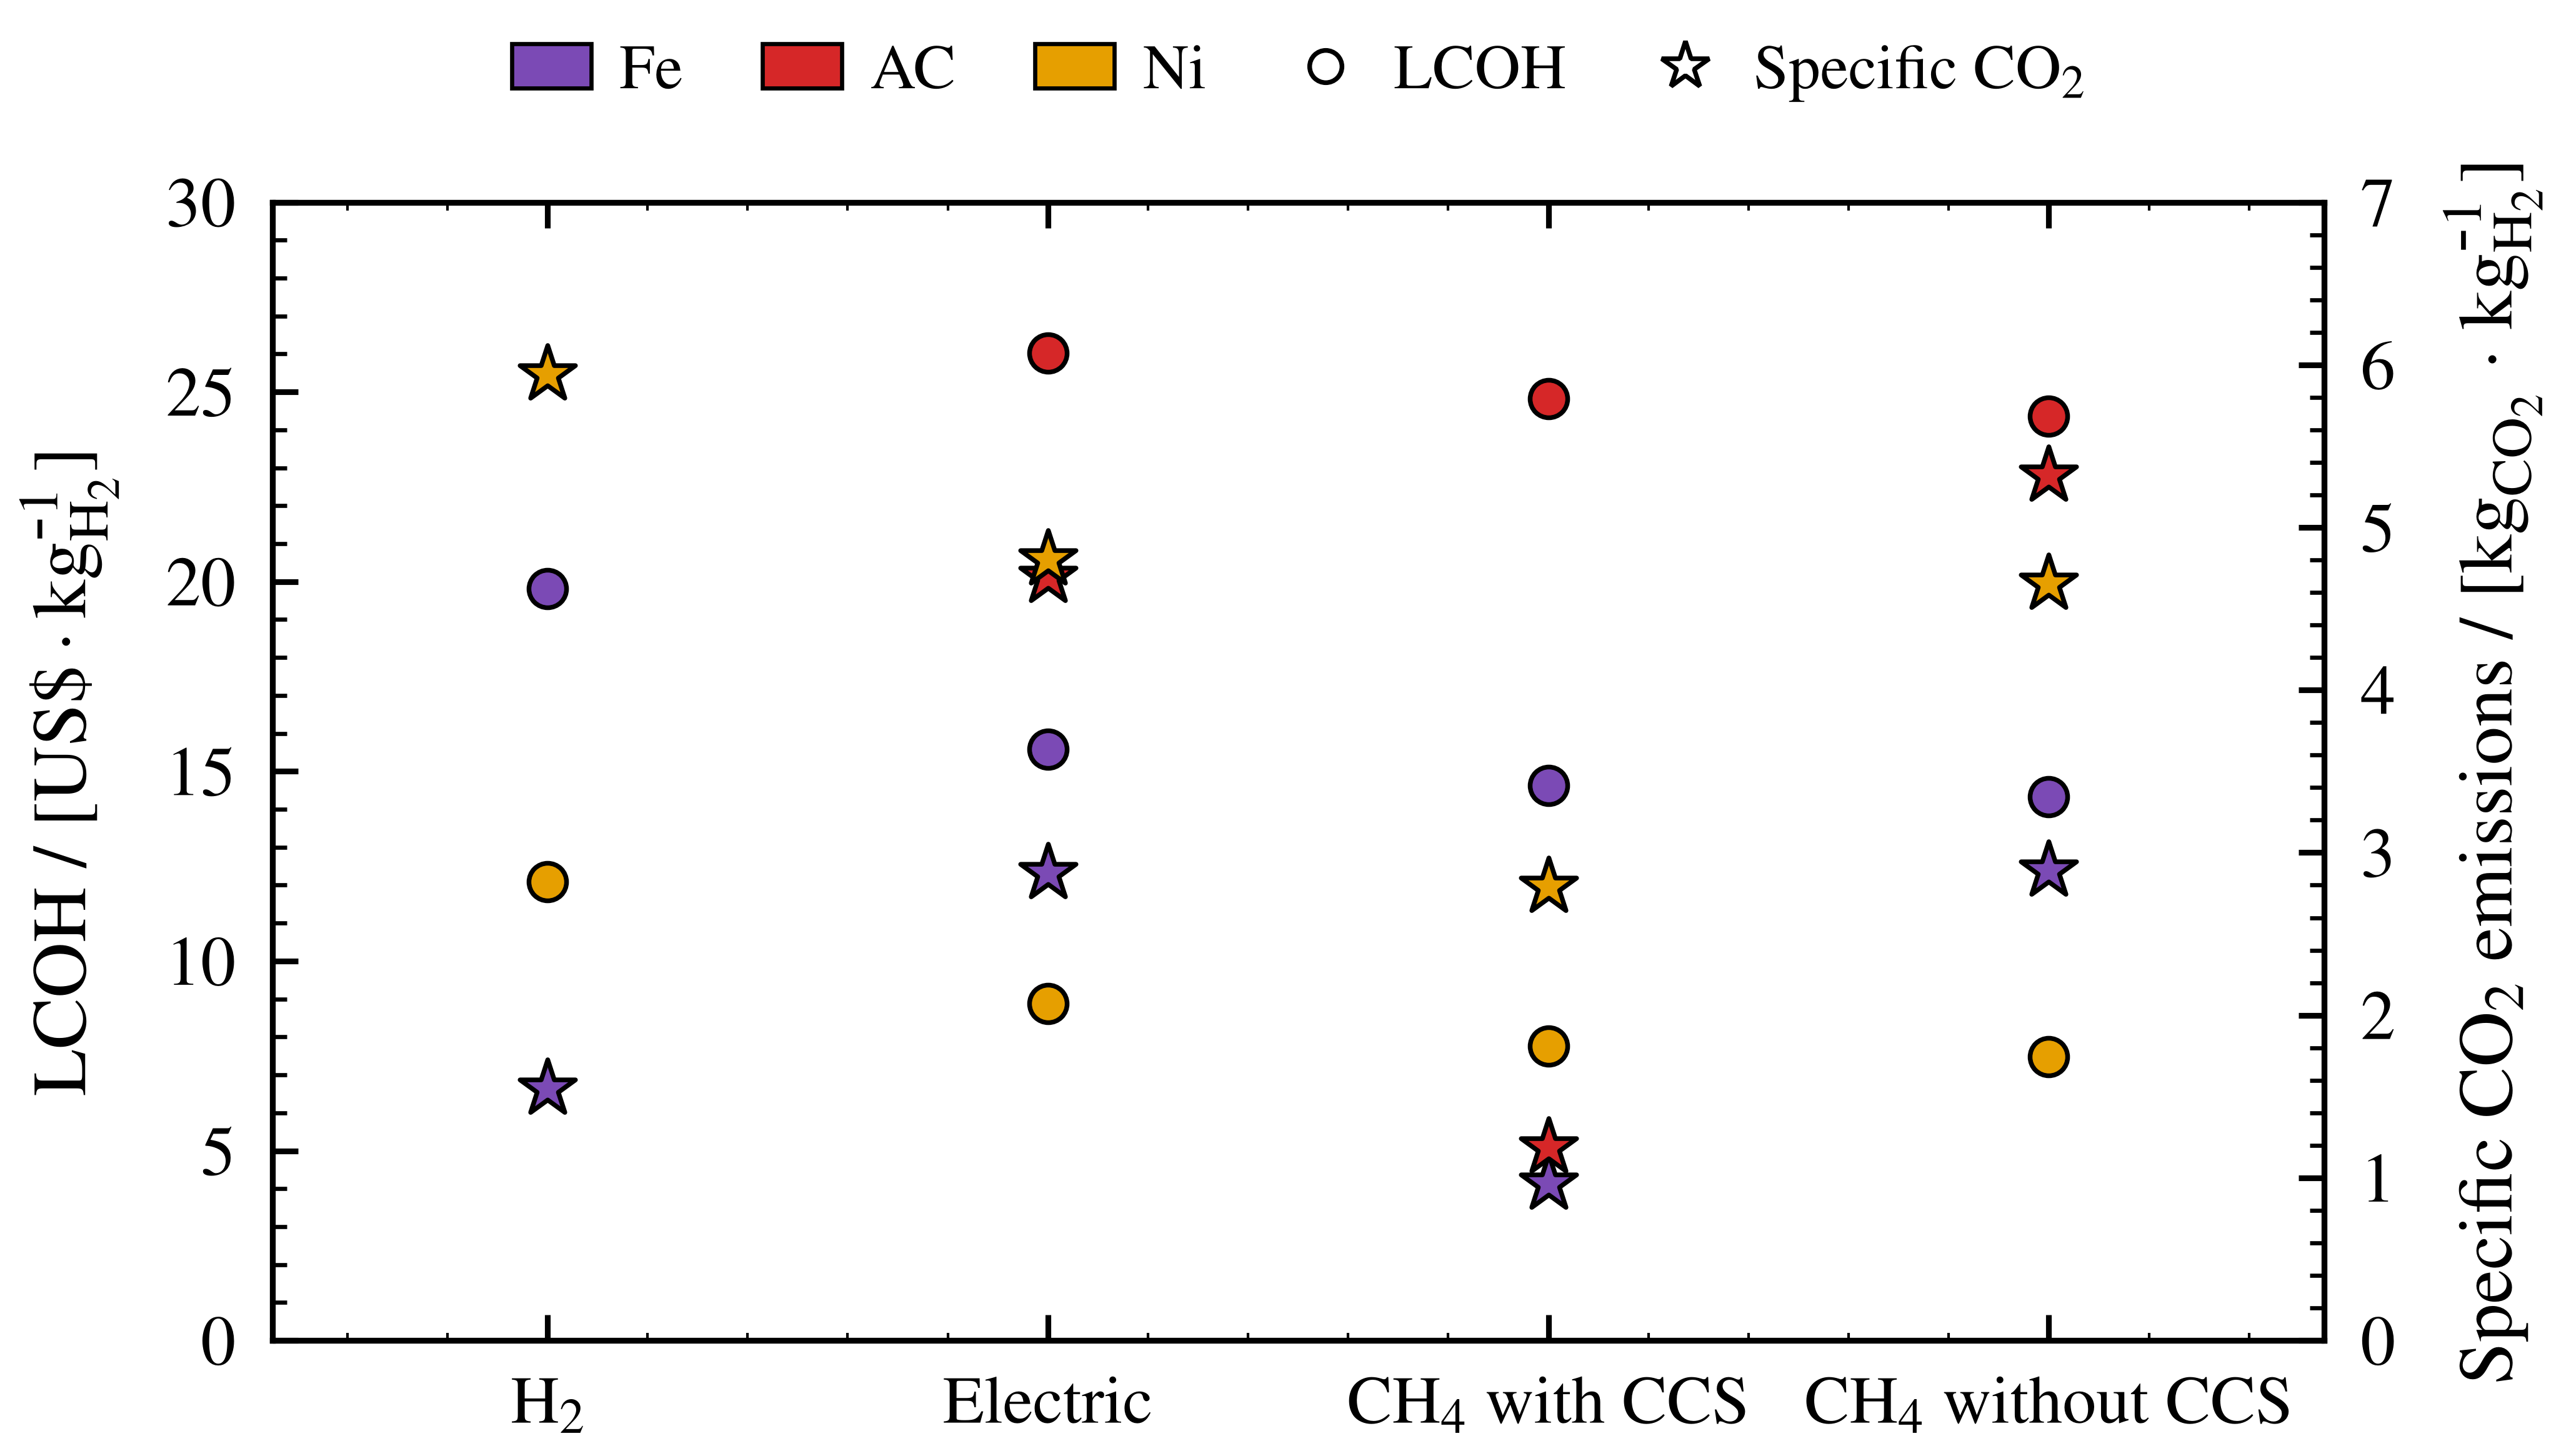

In [2]:
# Heating strategies plot: LCOH (circles, left axis) + specific CO2 emissions (stars, right axis)
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401  (registers the "science" styles)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator

# ----------------------------------------------------------------------------
# Style
# ----------------------------------------------------------------------------
TICK_FONT = 13.5
XLABEL_FONT = 13.0
AXIS_LABEL_FONT = 14.8
LEGEND_FONT = 12.2

plt.style.use(["science", "ieee"])
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": TICK_FONT,
    "axes.labelsize": AXIS_LABEL_FONT,
    "xtick.labelsize": XLABEL_FONT,
    "ytick.labelsize": TICK_FONT,
    "legend.fontsize": LEGEND_FONT,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

CATALYST_COLORS = {"Fe": "#7B4AB5", "AC": "#D62728", "Ni": "#E69F00"}

# Display labels; the dict order is also the preferred x-axis order
STRATEGY_LABELS = {
    "H2": r"$\mathrm{H_2}$",
    "Electric": "Electric",
    "CH4_with_CCS": r"$\mathrm{CH_4}$ with CCS",
    "CH4_without_CCS": r"$\mathrm{CH_4}$ without CCS",
}

MAJOR_TICKS = dict(direction="in", length=4.9, width=1.1, colors="black", pad=7)
MINOR_TICKS = dict(direction="in", length=2.8, width=0.8, colors="black")
MARKER_STYLE = dict(edgecolor="black", linewidth=0.9)


# ----------------------------------------------------------------------------
# Helpers
# ----------------------------------------------------------------------------
def strategies_with_both_results(data):
    """Heating strategies that have both an LCOH and a CO2 value."""
    return set(data["lcoh"]) & set(data["co2"])


def nice_ymax(values, step, minimum):
    """Add 8% headroom to the largest value and round up to a multiple of `step`."""
    return max(minimum, np.ceil(max(values) * 1.08 / step) * step)


def format_y_axis(ax, ymax, major_step, minor_step):
    ax.set_ylim(0, ymax)
    ax.yaxis.set_major_locator(MultipleLocator(major_step))
    ax.yaxis.set_minor_locator(MultipleLocator(minor_step))


# ----------------------------------------------------------------------------
# Strategies on the x-axis: preferred ones first, then any others found
# ----------------------------------------------------------------------------
available = set().union(*(strategies_with_both_results(d) for d in catalysts.values()))
if not available:
    raise ValueError("No common LCOH/CO2 heating strategies were found.")

strategies = [s for s in STRATEGY_LABELS if s in available]
strategies += sorted(available - set(STRATEGY_LABELS))

x = np.arange(len(strategies))
x_labels = [STRATEGY_LABELS.get(s, s) for s in strategies]


# ----------------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------------
fig, ax_lcoh = plt.subplots(figsize=(7.2, 4.6))
ax_co2 = ax_lcoh.twinx()

all_lcoh, all_co2 = [], []

for name, data in catalysts.items():
    color = CATALYST_COLORS[name]
    valid = strategies_with_both_results(data)

    for xi, strategy in zip(x, strategies):
        if strategy not in valid:
            continue

        lcoh = float(data["lcoh"][strategy])
        co2 = float(data["co2"][strategy])
        all_lcoh.append(lcoh)
        all_co2.append(co2)

        ax_lcoh.scatter(xi, lcoh, s=52, marker="o", facecolor=color, zorder=4, **MARKER_STYLE)
        ax_co2.scatter(xi, co2, s=125, marker="*", facecolor=color, zorder=5, **MARKER_STYLE)

# Left axis: LCOH
ax_lcoh.set_ylabel(r"LCOH / [US\$\,$\cdot$\,kg$_{\mathrm{H_2}}^{\mbox{-}1}$]", labelpad=9)
format_y_axis(ax_lcoh, nice_ymax(all_lcoh, step=5, minimum=5), major_step=5, minor_step=1)

# Right axis: specific CO2 emissions
ax_co2.set_ylabel(
    r"Specific $\mathrm{CO_2}$ emissions / "
    r"[$\mathrm{kg}_{\mathrm{CO_2}}\,\cdot\,\mathrm{kg}_{\mathrm{H_2}}^{\mbox{-}1}$]",
    labelpad=9,
)
format_y_axis(ax_co2, nice_ymax(all_co2, step=1.0, minimum=1.0), major_step=1.0, minor_step=0.2)

# x-axis
ax_lcoh.set_xticks(x)
ax_lcoh.set_xticklabels(x_labels)
ax_lcoh.set_xlim(-0.55, len(strategies) - 0.45)

# Ticks: LCOH ticks on the left only, CO2 ticks on the right only
ax_lcoh.tick_params(axis="x", which="major", top=True, bottom=True, **MAJOR_TICKS)
ax_lcoh.tick_params(axis="y", which="major", left=True, right=False, **MAJOR_TICKS)
ax_lcoh.tick_params(axis="y", which="minor", left=True, right=False, **MINOR_TICKS)
ax_co2.tick_params(axis="y", which="major", left=False, right=True, **MAJOR_TICKS)
ax_co2.tick_params(axis="y", which="minor", left=False, right=True, **MINOR_TICKS)

for ax in (ax_lcoh, ax_co2):
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.1)

# Legend: catalyst colours + marker meaning
catalyst_handles = [
    Patch(facecolor=color, edgecolor="black", linewidth=0.8, label=name)
    for name, color in CATALYST_COLORS.items()
]
metric_handles = [
    Line2D([0], [0], marker="o", markersize=6.2, label="LCOH",
           linestyle="None", markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.9),
    Line2D([0], [0], marker="*", markersize=9.5, label=r"Specific $\mathrm{CO_2}$",
           linestyle="None", markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.9),
]
fig.legend(
    handles=catalyst_handles + metric_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.965),
    ncol=5,
    frameon=False,
    columnspacing=1.25,
    handlelength=1.25,
    handletextpad=0.45,
)

fig.subplots_adjust(left=0.12, right=0.88, bottom=0.18, top=0.84)
fig.savefig("heating_strategies.pdf", format="pdf")
plt.show()

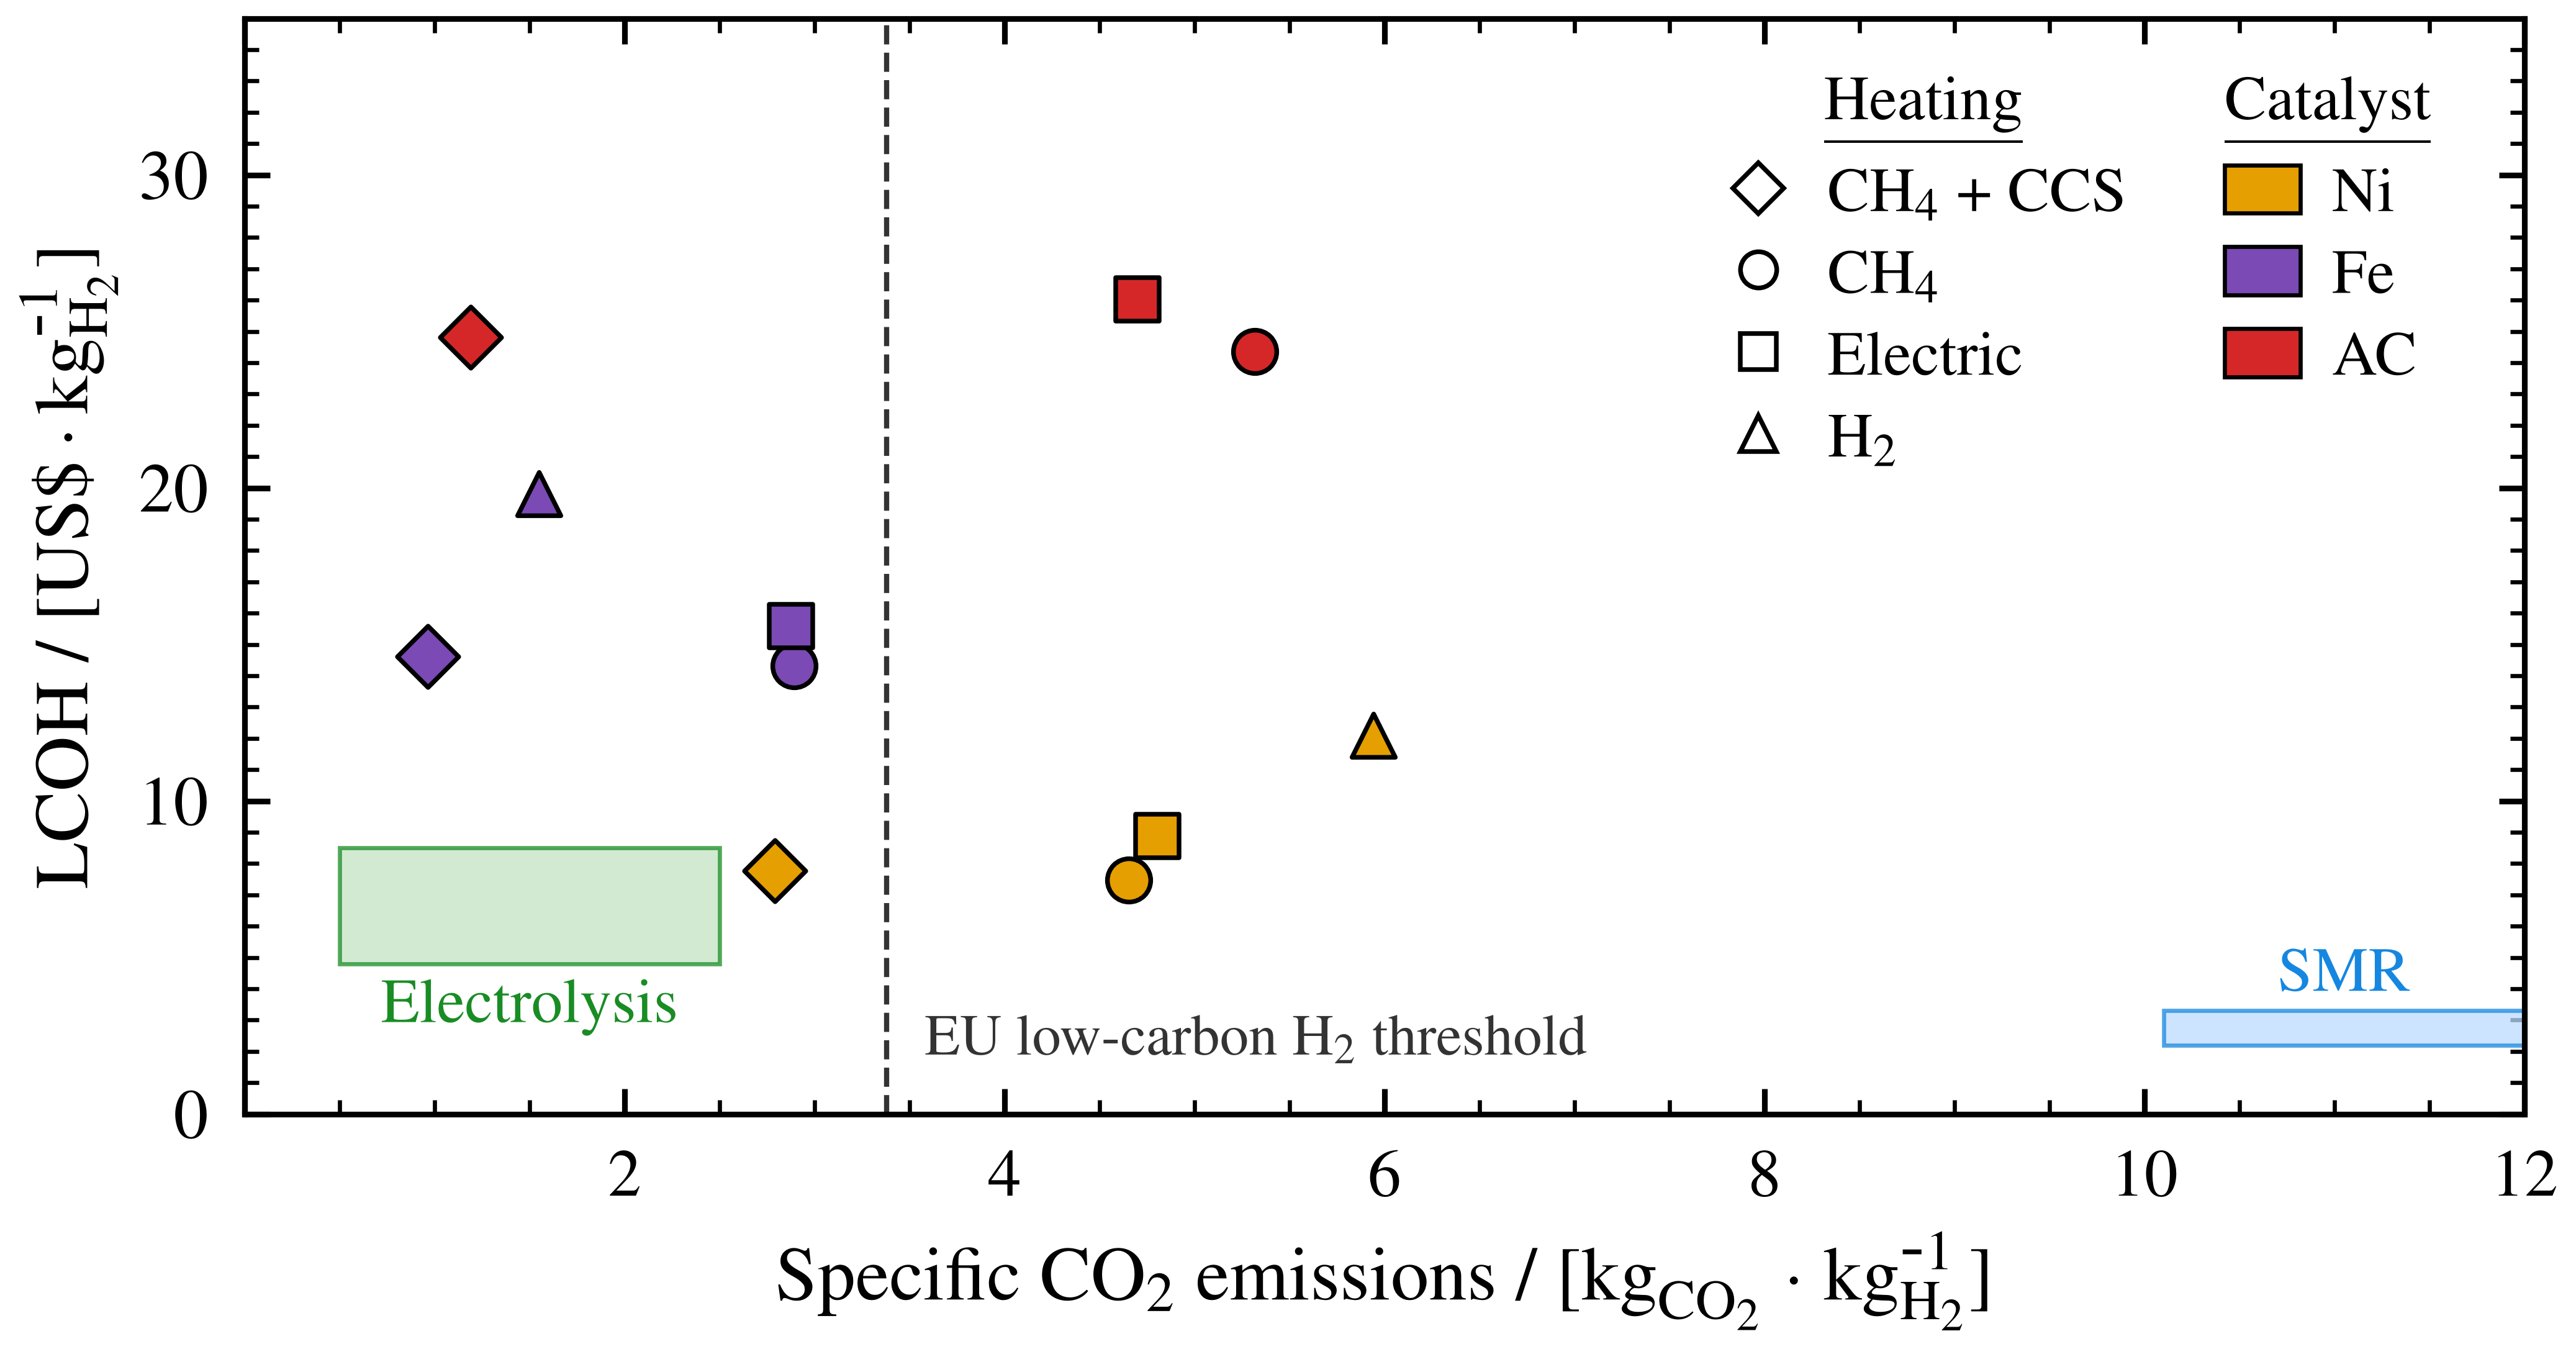

In [3]:
# Trade-off plot: LCOH vs specific CO2 emissions (lower-left is better)
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter, MultipleLocator

# Marker shape per heating strategy (colour = catalyst, from CATALYST_COLORS)
STRATEGY_MARKERS = {
    "H2": "^",
    "Electric": "s",
    "CH4_without_CCS": "o",
    "CH4_with_CCS": "D",
}

# Reference ranges for conventional routes
#   lcoh: US$/kg H2 (same as LCOH_Temperature.ipynb)
#   co2:  kg CO2/kg H2 (electrolysis = renewable-powered)
#   label_y / va: label placed just above/below the box so it never hides points
REFERENCE_RANGES = {
    "SMR": dict(lcoh=(2.2, 3.3), co2=(10.1, 17.2), label_y=3.5, va="bottom",
                fill="#bcdcff", text="#1687e0"),
    "Electrolysis": dict(lcoh=(4.8, 8.5), co2=(0.5, 2.5), label_y=4.3, va="top",
                         fill="#c3e3c3", text="#198c24"),
}

# EU low-carbon H2 threshold: 70 % below the 94 gCO2e/MJ fossil comparator
# (LHV 120 MJ/kg) = 3.38 kgCO2e/kgH2. Only meaningful if our CO2 boundary matches.
EU_LOW_CARBON_THRESHOLD = 3.38
THRESHOLD_COLOR = "0.2"

# Axis limits
X_MAX = 12
Y_MAX = 35


fig, ax = plt.subplots(figsize=(7.2, 3.5))

# Reference boxes: CO2 range (x) by LCOH range (y)
for label, ref in REFERENCE_RANGES.items():
    (x_low, x_high), (y_low, y_high) = ref["co2"], ref["lcoh"]
    ax.add_patch(Rectangle(
        (x_low, y_low), x_high - x_low, y_high - y_low,
        facecolor=ref["fill"], edgecolor=ref["text"], alpha=0.75, linewidth=0.8, zorder=1,
    ))
    # Centre the label on the visible part of the box (SMR runs past X_MAX)
    label_x = (x_low + min(x_high, X_MAX)) / 2
    ax.text(label_x, ref["label_y"], label, color=ref["text"],
            fontsize=LEGEND_FONT, ha="center", va=ref["va"], zorder=2)

# EU low-carbon threshold
ax.axvline(EU_LOW_CARBON_THRESHOLD, color=THRESHOLD_COLOR, lw=1.0, ls="--", zorder=2)
ax.text(EU_LOW_CARBON_THRESHOLD + 0.2, 1.5, r"EU low-carbon $\mathrm{H_2}$ threshold",
        color=THRESHOLD_COLOR, fontsize=LEGEND_FONT - 1, va="bottom", ha="left")

# Pyrolysis: one point per catalyst x heating strategy
for name, data in catalysts.items():
    for strategy in strategies_with_both_results(data):
        ax.scatter(
            float(data["co2"][strategy]),
            float(data["lcoh"][strategy]),
            s=70,
            marker=STRATEGY_MARKERS.get(strategy, "o"),
            facecolor=CATALYST_COLORS[name],
            edgecolor="black",
            linewidth=0.9,
            zorder=5,
        )

# Axes
ax.set_xlabel(
    r"Specific $\mathrm{CO_2}$ emissions / "
    r"[$\mathrm{kg}_{\mathrm{CO_2}}\,\cdot\,\mathrm{kg}_{\mathrm{H_2}}^{\mbox{-}1}$]"
)
ax.set_ylabel(r"LCOH / [US\$\,$\cdot$\,$\mathrm{kg}_{\mathrm{H_2}}^{\mbox{-}1}$]")
ax.set_xlim(0, X_MAX)
ax.set_ylim(0, Y_MAX)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.xaxis.set_minor_locator(MultipleLocator(0.5))
# Hide the x-axis "0" so it doesn't crowd the y-axis "0" at the origin
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: "" if v == 0 else f"${v:g}$"))
ax.yaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_minor_locator(MultipleLocator(1))
# ax.grid(False, which="major", color="0.88", lw=0.6, zorder=0)
ax.set_axisbelow(True)

ax.tick_params(which="major", top=True, right=True, **MAJOR_TICKS)
ax.tick_params(which="minor", top=True, right=True, **MINOR_TICKS)
for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.1)

# Legends: colour = catalyst, shape = heating strategy
CATALYST_LEGEND_ORDER = ["Ni", "Fe", "AC"]  # top to bottom
catalyst_handles = [
    Patch(facecolor=CATALYST_COLORS[name], edgecolor="black", linewidth=0.8, label=name)
    for name in CATALYST_LEGEND_ORDER
]
# Legend labels for this plot (shorter than the x-axis labels of the plot above)
legend_labels = {
    **STRATEGY_LABELS,
    "CH4_with_CCS": r"$\mathrm{CH_4}$ + CCS",
    "CH4_without_CCS": r"$\mathrm{CH_4}$",
}
# Legend order, top to bottom; any other strategy found goes at the end
LEGEND_ORDER = ["CH4_with_CCS", "CH4_without_CCS", "Electric", "H2"]
legend_order = sorted(strategies, key=lambda s: LEGEND_ORDER.index(s) if s in LEGEND_ORDER else len(LEGEND_ORDER))
strategy_handles = [
    Line2D([0], [0], marker=STRATEGY_MARKERS[s], linestyle="None", markersize=7,
           markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.9,
           label=legend_labels[s])
    for s in legend_order
]
# Two titled legend columns side by side in the empty upper-right corner:
# "Heating" (marker shape) on the left, "Catalyst" (colour) on the right
legend_style = dict(frameon=False, handlelength=1.2, handleheight=0.8, handletextpad=0.5,
                    labelspacing=0.35, borderaxespad=0.0, alignment="left",
                    title_fontsize=LEGEND_FONT)
TOP_RIGHT = (0.97, 0.97)  # axes coordinates
COLUMN_GAP = 0.01         # axes fraction between the two columns

catalyst_legend = ax.legend(handles=catalyst_handles, title=r"\underline{Catalyst}",
                            loc="upper right", bbox_to_anchor=TOP_RIGHT, **legend_style)
ax.add_artist(catalyst_legend)  # keep it when the second legend is added

# Place the heating column just left of the catalyst column, tops aligned
fig.canvas.draw()
catalyst_box = catalyst_legend.get_window_extent().transformed(ax.transAxes.inverted())
ax.legend(handles=strategy_handles, title=r"\underline{Heating}",
          loc="upper right", bbox_to_anchor=(catalyst_box.x0 - COLUMN_GAP, TOP_RIGHT[1]),
          **{**legend_style, "alignment": "center"})  # centre the "Heating" title

fig.subplots_adjust(left=0.11, right=0.96, bottom=0.13, top=0.97)
fig.savefig("figure-8.pdf", format="pdf", dpi=500)
plt.show()